正在读取数据文件...
数据维度: (20001, 21)
行数(基因数): 20001
列数(细胞类型数): 21

前5行数据:

缺失值数量: 0

正在计算基因方差...

选取前50个高变基因进行聚类分析
正在进行数据标准化...
正在生成聚类热图...


<Figure size 4800x3600 with 0 Axes>

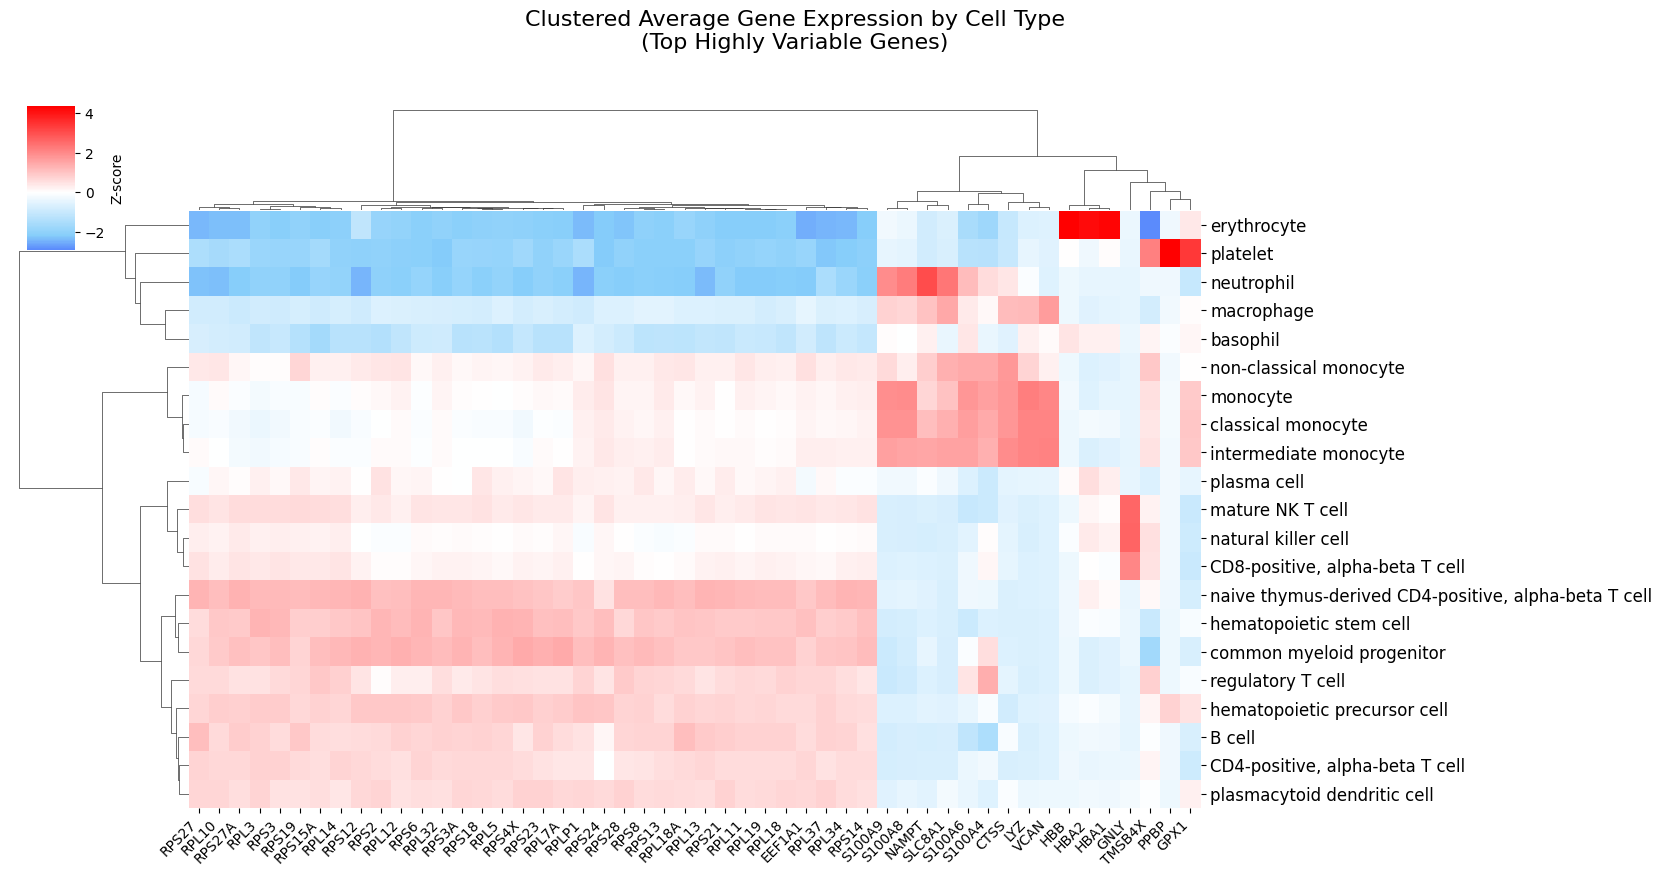

In [2]:
### 探索血液细胞表达谱，2025.9.20
# AI提问：用Python语言读入blood mean expr.csv数据文件，每一列是细胞类型，每一行是基因。
# 选取100个高变基因做聚类热图
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import pdist
from matplotlib.colors import LinearSegmentedColormap

# 1. 读取数据文件
print("正在读取数据文件...")
blood_df = pd.read_csv('Output/blood mean expr.csv', index_col=0)

blood_df = blood_df.drop(columns=["myeloid dendritic cell"]) # 包含较多0值的样本

# 2. 检查数据基本信息
print(f"数据维度: {blood_df.shape}")
print(f"行数(基因数): {blood_df.shape[0]}")
print(f"列数(细胞类型数): {blood_df.shape[1]}")

print("\n前5行数据:")
#print(df.head())

# 3. 检查是否有缺失值
missing_values = blood_df.isnull().sum().sum()
print(f"\n缺失值数量: {missing_values}")

# 4. 计算基因的方差以识别高变基因
print("\n正在计算基因方差...")
gene_variances = blood_df.var(axis=1).sort_values(ascending=False)

#print("方差最大的前10个基因:")
#print(gene_variances.head(10))

# 5. 选取前100个高变基因
n_highly_variable = min(50, len(gene_variances))
high_var_genes = gene_variances.head(n_highly_variable).index.tolist()

print(f"\n选取前{n_highly_variable}个高变基因进行聚类分析")

# 6. 提取高变基因的表达数据
high_var_expression = blood_df.loc[high_var_genes]

# 7. 对数据进行标准化处理（Z-score）
print("正在进行数据标准化...")
scaler = StandardScaler()
scaled_data = scaler.fit_transform(high_var_expression.T).T  # 转置后标准化再转置回来
scaled_df = pd.DataFrame(scaled_data, 
                        index=high_var_expression.index, 
                        columns=high_var_expression.columns)

# 8. 创建饱和的红白蓝配色方案
print("正在生成聚类热图...")

# 创建高度饱和的红白蓝颜色映射
saturated_colors = [(0.0, '#0000FF'),    # 纯蓝色
                    (0.25, '#87CEFA'),   # 浅蓝色
                    (0.5, '#FFFFFF'),    # 白色
                    (0.75, '#FF7F7F'),   # 浅红色
                    (1.0, '#FF0000')]    # 纯红色

saturated_cmap = LinearSegmentedColormap.from_list('saturated_red_white_blue', saturated_colors, N=256)

# 9. 绘制聚类热图
plt.figure(figsize=(16, 12), dpi=300)

# 使用seaborn的clustermap进行聚类热图绘制
g = sns.clustermap(scaled_df.T, 
                   cmap=saturated_cmap,  # 饱和红白蓝配色
                   center=0,
                   figsize=(16, 8),
                   linewidths=0,  # 设置线宽为0以去除白线
                   cbar_pos=(0.02, 0.8, 0.03, 0.18),  # 调整颜色条位置和大小
                   cbar_kws={"label": "Z-score"},
                   xticklabels=True,
                   yticklabels=True,
                   row_cluster=True,   # 对行（基因）进行聚类
                   col_cluster=True,   # 对列（细胞类型）进行聚类
                   dendrogram_ratio=0.15,  # 调整树状图比例
                   colors_ratio=0.03,  # 调整颜色条比例
                   metric='euclidean',  # 距离度量
                   method='ward')       # 聚类方法

# 设置标题
g.fig.suptitle('Clustered Average Gene Expression by Cell Type\n(Top Highly Variable Genes)', 
               fontsize=16, y=1.1)

# 调整标签显示
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right', fontsize=10)
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=12)
plt.show()

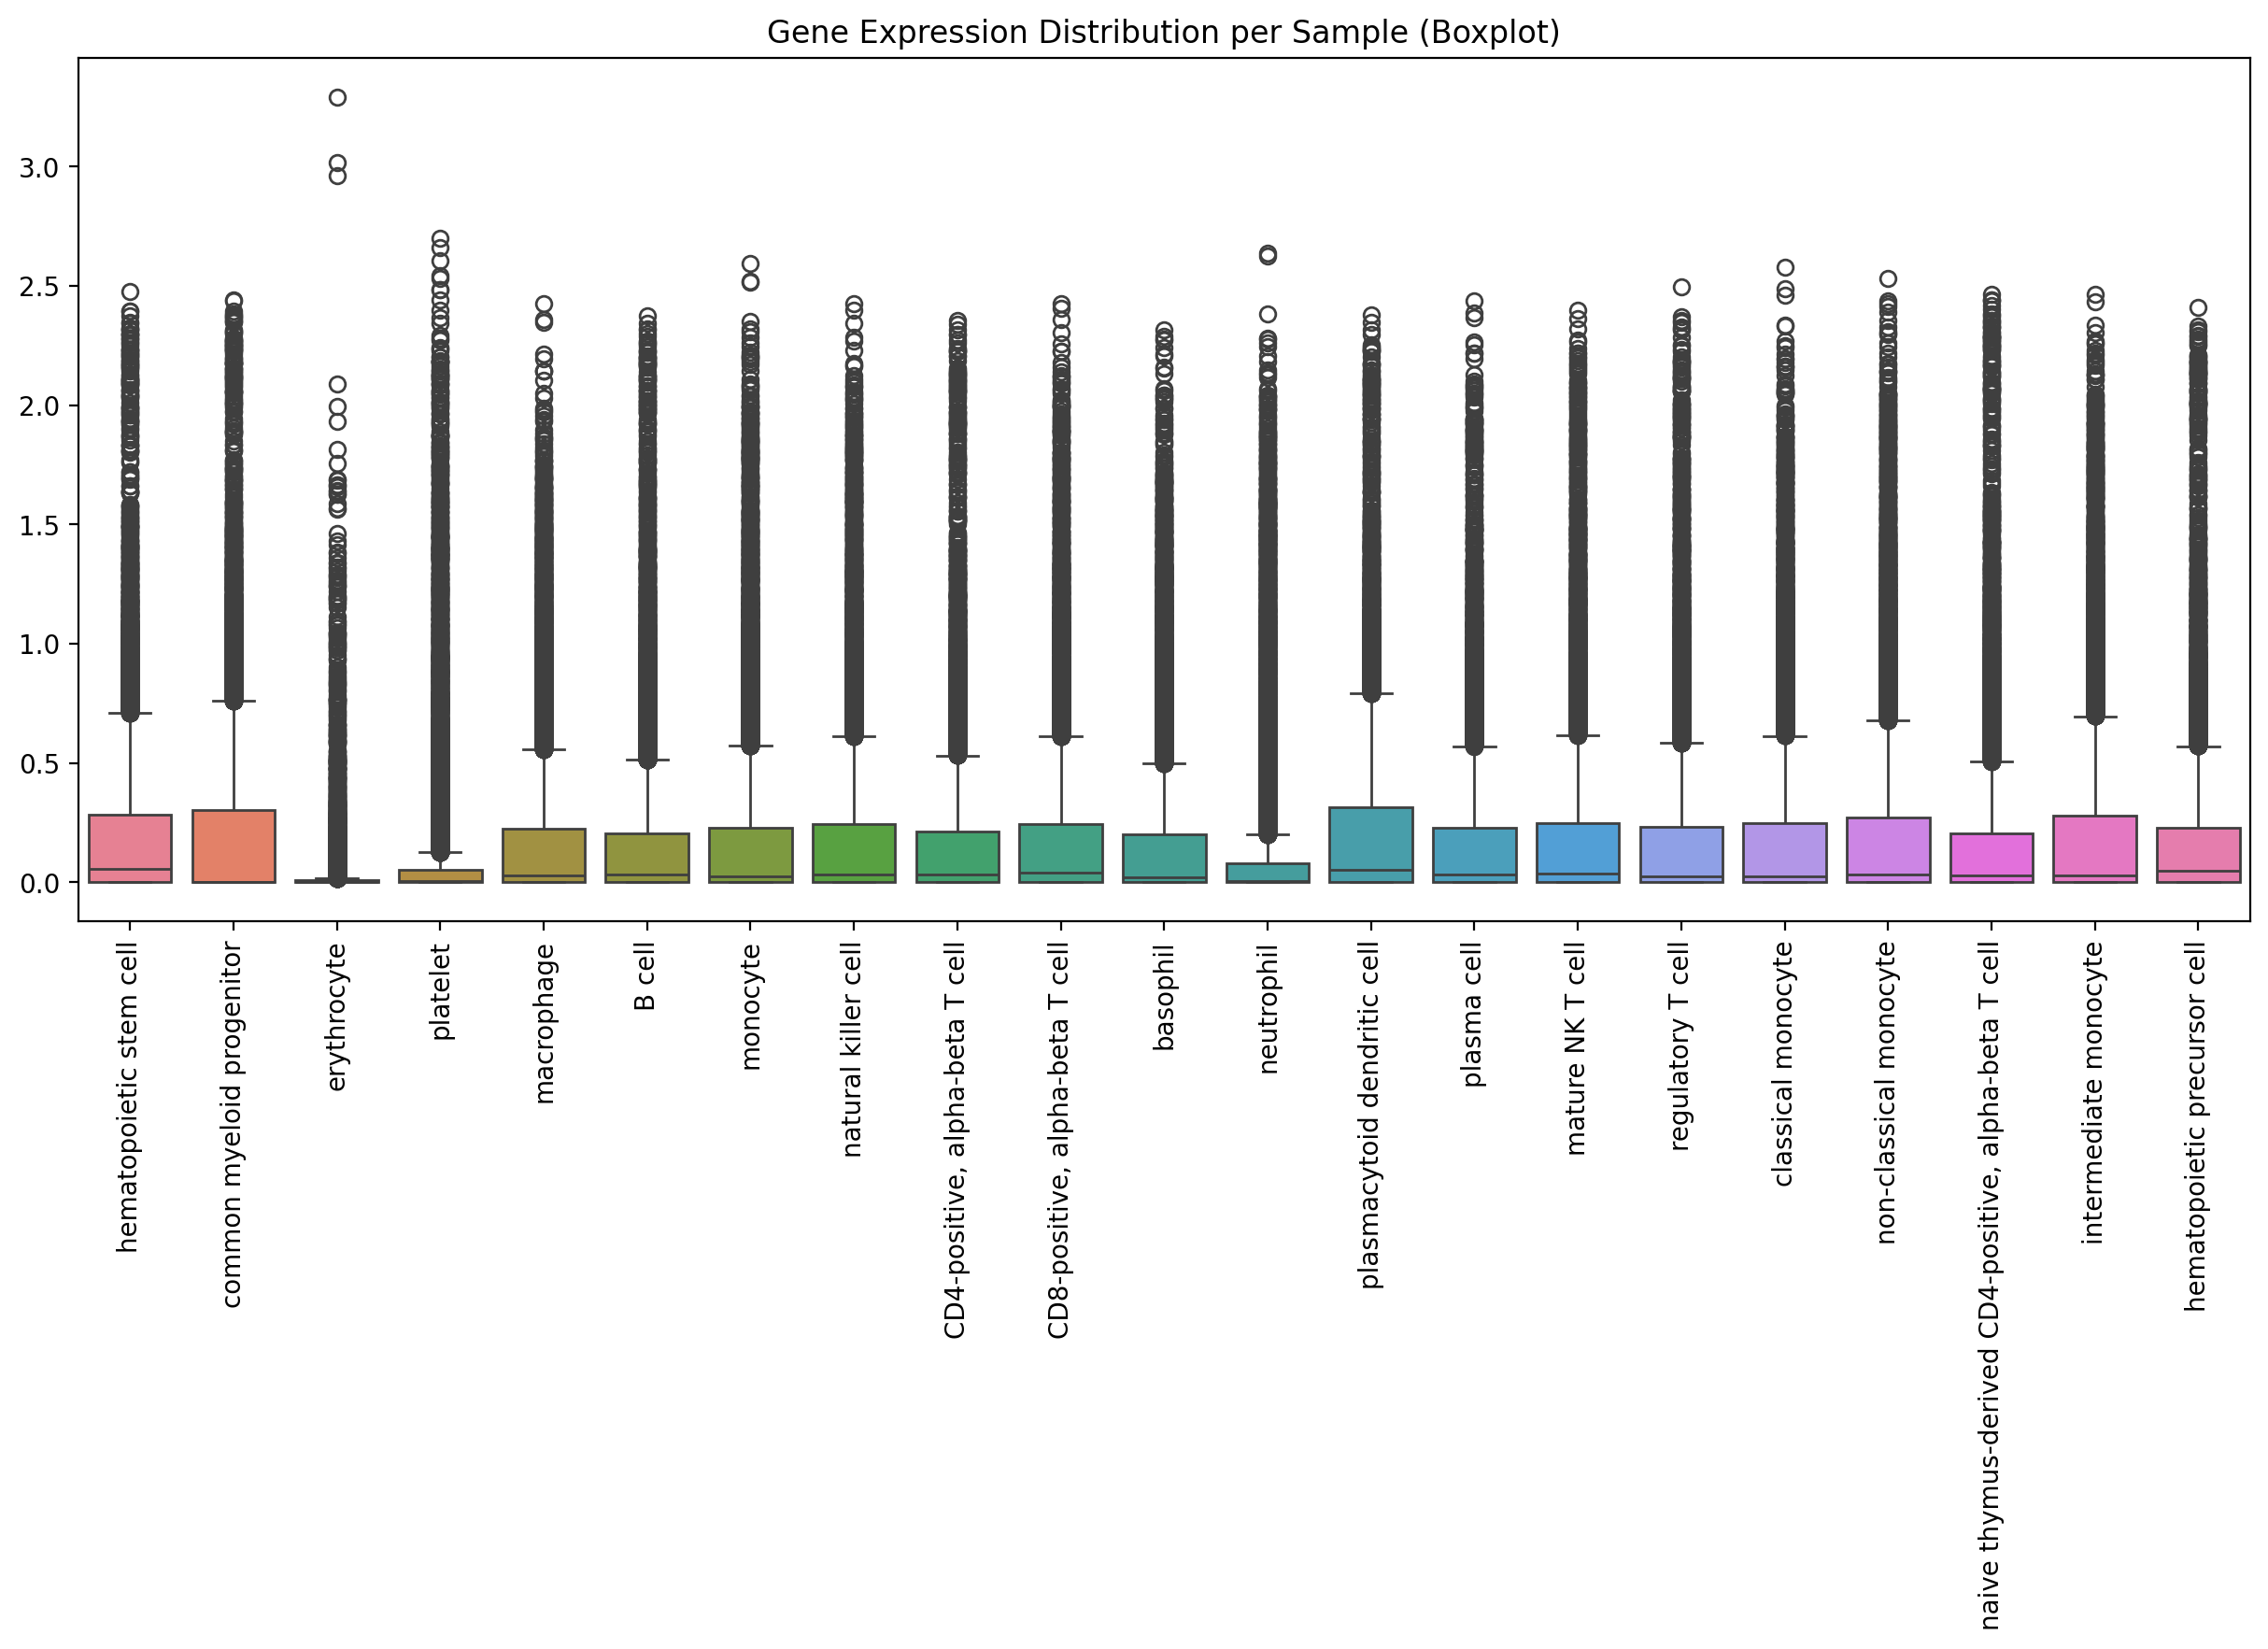

In [3]:
### 绘制单个样本的分布，箱线图（Boxplot）
plt.figure(figsize=(15, 6), dpi=200)
# 对数据取对数（log1p = log(1+x)，避免log(0)）
data_log = np.log2(blood_df + 1)

sns.boxplot(data = data_log)  # 转置数据，使样本为行
plt.xticks(rotation=90)
plt.title("Gene Expression Distribution per Sample (Boxplot)")
plt.show()

Index(['hematopoietic stem cell', 'common myeloid progenitor', 'erythrocyte',
       'platelet', 'macrophage', 'B cell', 'monocyte', 'natural killer cell',
       'CD4-positive, alpha-beta T cell', 'CD8-positive, alpha-beta T cell'],
      dtype='object')


<Figure size 4800x4800 with 0 Axes>

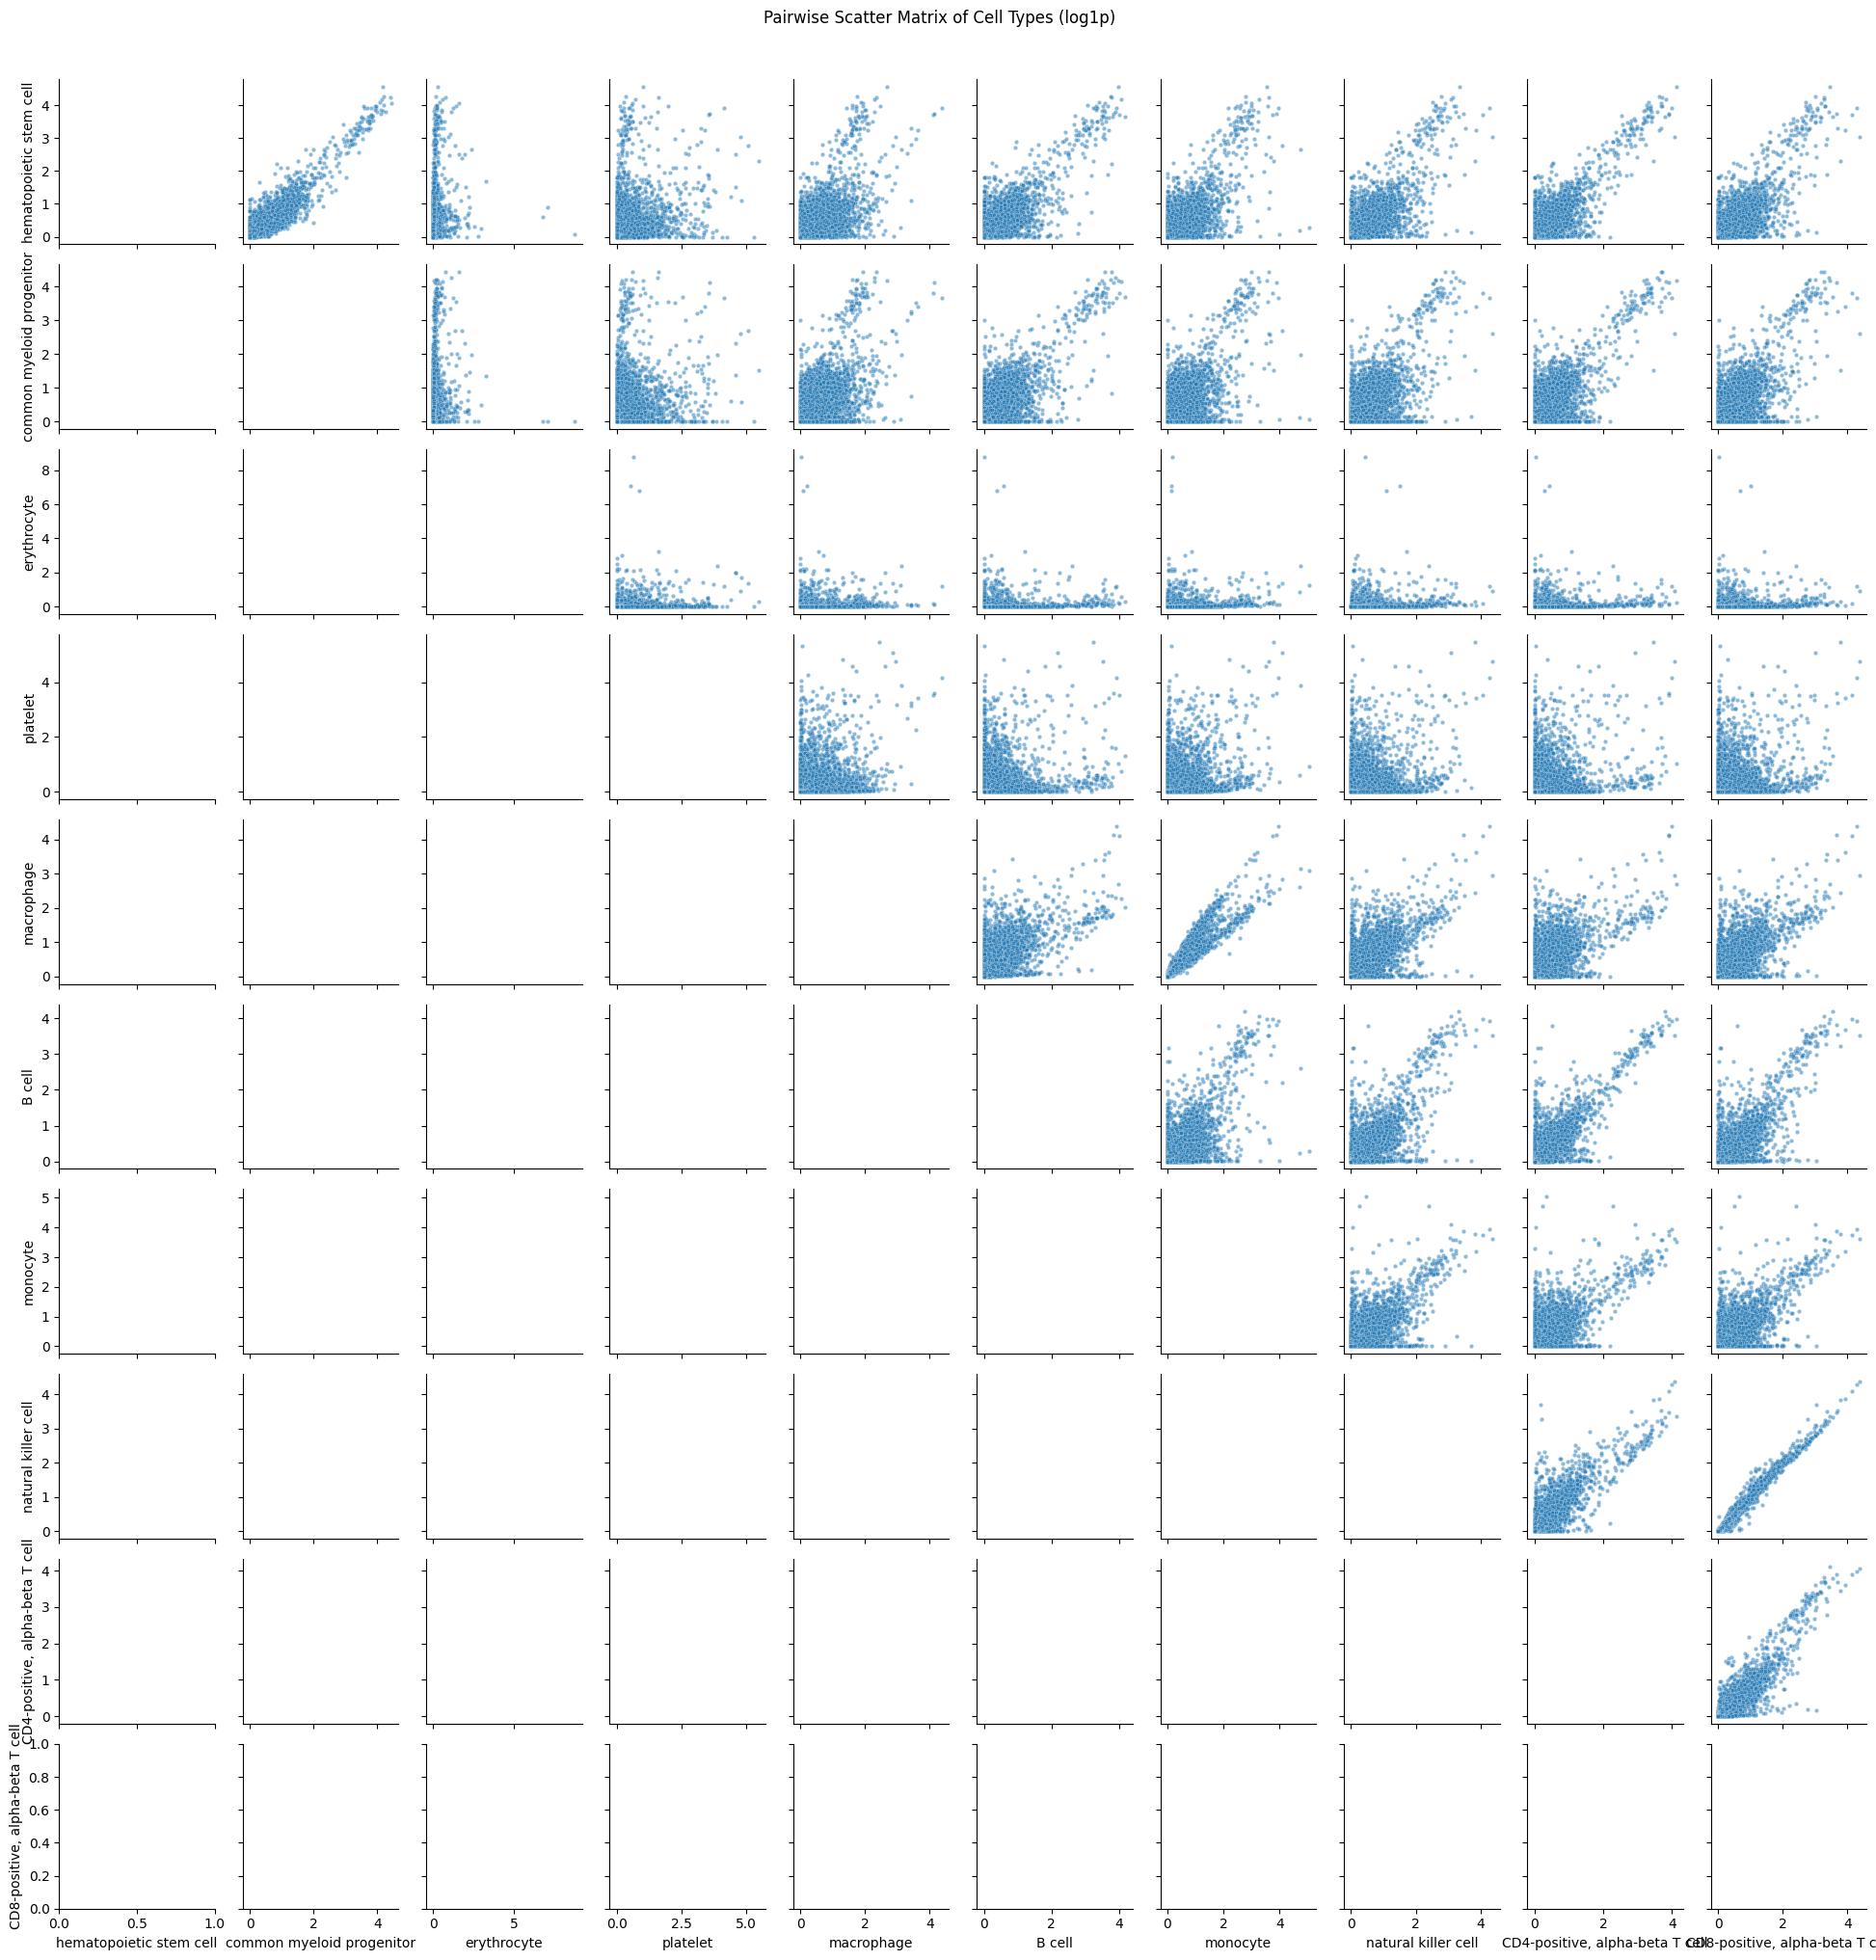

In [4]:
### 绘制两两细胞类型的散点图

plt.figure(figsize=(16, 16), dpi=300)
# 设置全局DPI为300
#plt.rcParams['figure.dpi'] = 300

# 选择部分细胞类型（避免图形过于密集）
selected_cell_types = blood_df.columns[:10]  # 例如前5个细胞类型
print(selected_cell_types)

# 使用 seaborn 的 PairGrid
g = sns.PairGrid(blood_df[selected_cell_types], height=2)
g.map_upper(sns.scatterplot, alpha=0.5, s=10)  # 上三角：散点图
#g.map_diag(sns.histplot, kde=True)             # 对角线：分布直方图
#g.map_lower(sns.kdeplot, cmap='Blues_d')       # 下三角：密度图
plt.suptitle('Pairwise Scatter Matrix of Cell Types (log1p)', y=1.02)
plt.show()

In [5]:
### 读取L1000表达量数据的子集，与Tabula数据关联，2025.9.25
import pandas as pd

h5_filename = "Output/L1000 MCF7_OE gene expression.h5"

# 读取HDF5文件
L1000_df = pd.read_hdf(h5_filename, key='expression')
print("\n从HDF5文件读取的数据框:")
print(f"★数据框形状: {L1000_df.shape}")
#print(df.head())

L1000_genes = L1000_df.index.tolist()        # 获取所有行名（基因符号）
column_names = L1000_df.columns.tolist()   # 获取所有列名（特征名称）

print("★L1000基因数:", len(L1000_genes))       # 12328
print("前10个行名:", L1000_genes[:10])

print("列数:", len(column_names))    # 2717
print("前10个列名:", column_names[:10])

blood_genes = blood_df.index.tolist() 
print("★Blood基因数:", len(blood_genes))   
print("前10个行名:", blood_genes[:10])

# L1000和Blood基因的交集
intersection = list(set(L1000_genes) & set(blood_genes))

print(f"\n★L1000和Blood基因的交集:")
print(f"交集基因数量: {len(intersection)}")
print(f"交集基因列表: {sorted(intersection)[:20]}")  # 排序以便更好地展示


从HDF5文件读取的数据框:
★数据框形状: (12328, 2717)
★L1000基因数: 12328
前10个行名: ['NAT2', 'ADA', 'CDH2', 'AKT3', 'MED6', 'NAALAD2', 'NAALADL1', 'ACOT8', 'ABI1', 'GNPDA1']
列数: 2717
前10个列名: ['NDUFB1', 'SET', 'HMGN3', 'TSC22D3', 'LSM6', 'DUSP22', 'DYNLL2', 'S100A6', 'MLLT11', 'S100P']
★Blood基因数: 20001
前10个行名: ['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH', 'FUCA2', 'GCLC', 'NFYA']

★L1000和Blood基因的交集:
交集基因数量: 11940
交集基因列表: ['A1CF', 'A2M', 'A4GALT', 'A4GNT', 'AAAS', 'AACS', 'AADAC', 'AAGAB', 'AAK1', 'AAMDC', 'AAMP', 'AANAT', 'AAR2', 'AARSD1', 'AASDHPPT', 'AASS', 'AATF', 'AATK', 'ABAT', 'ABCA1']


In [19]:
### AI提问：使用Lasso回归建立从L1000表达谱L1000_df到血液细胞表达谱blood_df的预测模型
# 2025.9.25
### 数据预处理
import pandas as pd
import numpy as np
from sklearn.linear_model import LassoCV, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 数据对齐（确保共有基因）
common_genes = list(set(L1000_df.index) & set(blood_df.index))
print(f"共有基因数: {len(common_genes)}")

X = L1000_df.loc[common_genes].iloc[:, :500]      # L1000表达谱 (基因 × 扰动)
Y = blood_df.loc[common_genes]      # 血液细胞表达谱 (基因 × 细胞类型)

# 去除重复行（保留第一个）
if X.index.duplicated().any():
    X = X[~X.index.duplicated(keep='first')]
    print(f"X去重后维度: {X.shape}")

if Y.index.duplicated().any():
    Y = Y[~Y.index.duplicated(keep='first')]
    print(f"Y去重后维度: {Y.shape}")

# 2. 数据标准化
scaler_X = StandardScaler()
scaler_Y = StandardScaler()

X_scaled = pd.DataFrame(
    scaler_X.fit_transform(X.T).T,  # 转置标准化
    index=X.index,
    columns=X.columns
)

Y_scaled = pd.DataFrame(
    scaler_Y.fit_transform(Y.T).T,
    index=Y.index,
    columns=Y.columns
)

print(f"L1000数据维度: {X_scaled.shape}")    # (基因数, 扰动数)
print(f"血液数据维度: {Y_scaled.shape}")     # (基因数, 细胞类型数)

共有基因数: 11940
X去重后维度: (11940, 500)
Y去重后维度: (11940, 21)
L1000数据维度: (11940, 500)
血液数据维度: (11940, 21)


In [20]:
### Lasso回归建模（每个细胞类型分别建模）
# 对每个血液细胞类型建立独立的Lasso模型
lasso_models = {}
model_performance = {}

print(Y_scaled.columns)
HSC = Y_scaled.columns[0]
for cell_type in Y_scaled.columns[1:]:
    print(f"正在训练从HSC转化为 {cell_type} 的预测模型...")
    
    #y = Y_scaled[cell_type].values  # 当前细胞类型的表达谱
    y = Y_scaled[cell_type].values - Y_scaled[HSC].values # 两种细胞类型的差值
    
    # Lasso交叉验证选择最优α
    lasso_cv = LassoCV(
        alphas=np.logspace(-4, 2, 100),  # 扩展α搜索范围
        cv=5,                            # 5折交叉验证
        random_state=42,
        max_iter=3000,
        tol=1e-4
    )
    
    # 训练模型
    #lasso_cv.fit(X_scaled.T, y)  # X转置为(扰动数 × 基因数)
    lasso_cv.fit(X_scaled, y) 
    
    # 存储模型和性能
    lasso_models[cell_type] = lasso_cv
    model_performance[cell_type] = {
        'alpha': lasso_cv.alpha_,
        'r2_cv': lasso_cv.score(X_scaled, y),
        'mse_cv': np.mean((y - lasso_cv.predict(X_scaled))**2),
        'non_zero_features': np.sum(lasso_cv.coef_ != 0),
        'sparsity': np.sum(lasso_cv.coef_ == 0) / len(lasso_cv.coef_)
    }

# 性能汇总
performance_df = pd.DataFrame(model_performance).T
print("\n模型性能概览:")
print(performance_df[['r2_cv', 'non_zero_features', 'sparsity']].describe())

Index(['hematopoietic stem cell', 'common myeloid progenitor', 'erythrocyte',
       'platelet', 'macrophage', 'B cell', 'monocyte', 'natural killer cell',
       'CD4-positive, alpha-beta T cell', 'CD8-positive, alpha-beta T cell',
       'basophil', 'neutrophil', 'plasmacytoid dendritic cell', 'plasma cell',
       'mature NK T cell', 'regulatory T cell', 'classical monocyte',
       'non-classical monocyte',
       'naive thymus-derived CD4-positive, alpha-beta T cell',
       'intermediate monocyte', 'hematopoietic precursor cell'],
      dtype='object')
正在训练从HSC转化为 common myeloid progenitor 的预测模型...
正在训练从HSC转化为 erythrocyte 的预测模型...
正在训练从HSC转化为 platelet 的预测模型...


/root/miniforge3/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.146e+01, tolerance: 3.579e+00
  model = cd_fast.enet_coordinate_descent(


正在训练从HSC转化为 macrophage 的预测模型...


/root/miniforge3/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.255e+00, tolerance: 2.284e+00
  model = cd_fast.enet_coordinate_descent(


正在训练从HSC转化为 B cell 的预测模型...
正在训练从HSC转化为 monocyte 的预测模型...


...

正在训练从HSC转化为 mature NK T cell 的预测模型...
正在训练从HSC转化为 regulatory T cell 的预测模型...
正在训练从HSC转化为 classical monocyte 的预测模型...


/root/miniforge3/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.035e+01, tolerance: 2.462e+00
  model = cd_fast.enet_coordinate_descent(


正在训练从HSC转化为 non-classical monocyte 的预测模型...
正在训练从HSC转化为 naive thymus-derived CD4-positive, alpha-beta T cell 的预测模型...
正在训练从HSC转化为 intermediate monocyte 的预测模型...


/root/miniforge3/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.433e+01, tolerance: 2.505e+00
  model = cd_fast.enet_coordinate_descent(


正在训练从HSC转化为 hematopoietic precursor cell 的预测模型...

模型性能概览:
           r2_cv  non_zero_features  sparsity
count  20.000000          20.000000  20.00000
mean    0.263325         412.950000   0.17410
std     0.078938          50.705003   0.10141
min     0.085446         253.000000   0.07400
25%     0.229343         418.250000   0.12750
50%     0.260480         429.500000   0.14100
75%     0.308937         436.250000   0.16350
max     0.394015         463.000000   0.49400


In [21]:
### 系数矩阵构建与分析
# 构建扰动×细胞类型系数矩阵
perturbation_names = X_scaled.columns
cell_type_names = Y_scaled.columns[1:]

# 初始化系数矩阵
coef_matrix = pd.DataFrame(
    np.zeros((len(perturbation_names), len(cell_type_names))),
    index=perturbation_names,
    columns=cell_type_names
)

# 填充系数
for cell_type in cell_type_names:
    coef_matrix[cell_type] = lasso_models[cell_type].coef_

print(f"系数矩阵维度: {coef_matrix.shape}")
print(f"非零系数比例: {(coef_matrix != 0).sum().sum() / coef_matrix.size:.3f}")

系数矩阵维度: (500, 20)
非零系数比例: 0.826


Top 20 重要扰动:
          perturbation  importance  specificity  non_zero_count
cmap_name                                                      
PRKCE            PRKCE    0.127558     0.057808              19
NDUFB5          NDUFB5    0.125189     0.052595              19
PPM1B            PPM1B    0.115560     0.052209              19
RGS4              RGS4    0.111367     0.045729              19
IFIT5            IFIT5    0.111366     0.078859              18
QRSL1            QRSL1    0.108756     0.062434              20
NDUFB1          NDUFB1    0.104181     0.057944              20
F10                F10    0.099659     0.076519              18
EHHADH          EHHADH    0.097237     0.060216              18
IKBIP            IKBIP    0.096421     0.036422              20
HAGH              HAGH    0.093535     0.034946              20
GSTM2            GSTM2    0.093399     0.039878              19
SIRT6            SIRT6    0.089807     0.037716              20
CYP3A5          CYP3A5    0

/tmp/ipykernel_233/111273144.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


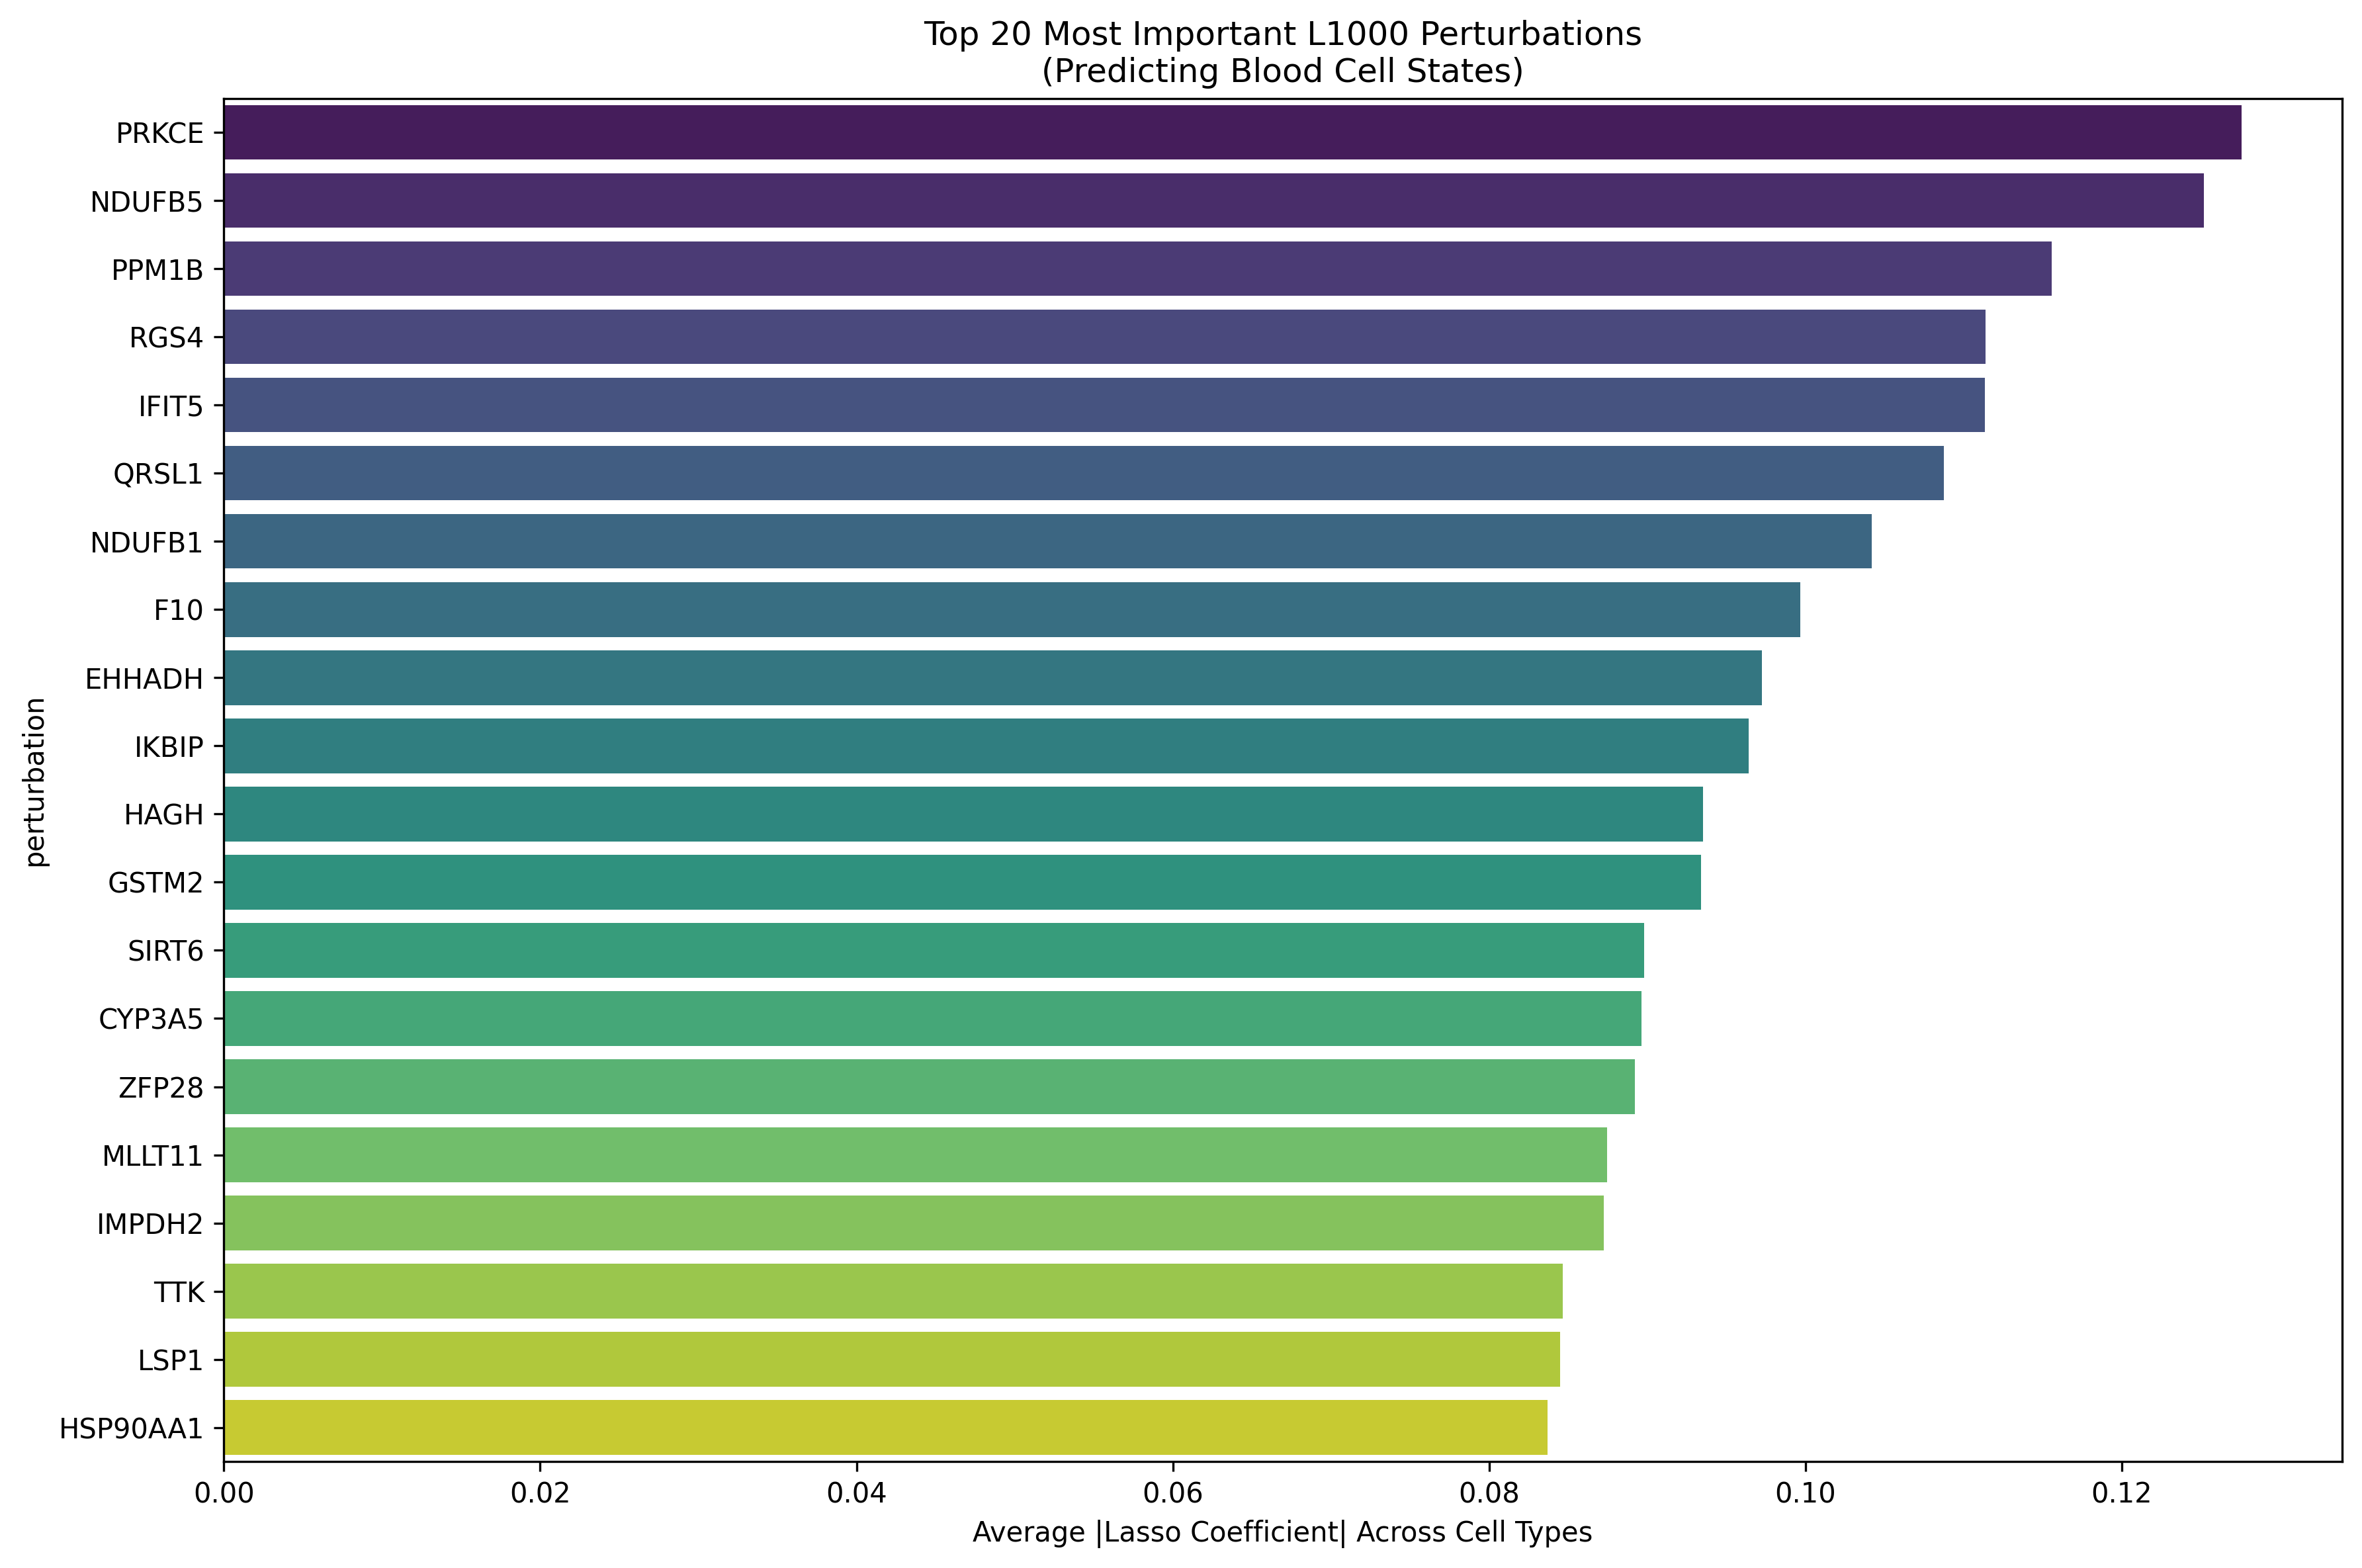

In [22]:
### 关键扰动识别
# 设置全局DPI为300
plt.rcParams['figure.dpi'] = 300

# 识别对血液细胞状态影响最大的L1000扰动
perturbation_importance = pd.DataFrame({
    'perturbation': perturbation_names,
    'importance': np.abs(coef_matrix).mean(axis=1),  # 平均重要性
    'specificity': np.abs(coef_matrix).std(axis=1),   # 特异性（标准差）
    'non_zero_count': (coef_matrix != 0).sum(axis=1)  # 影响细胞类型数
}).sort_values('importance', ascending=False)

print("Top 20 重要扰动:")
print(perturbation_importance.head(20))

# 可视化重要扰动
plt.figure(figsize=(12, 8))
top_perts = perturbation_importance.head(20)
sns.barplot(
    data=top_perts,
    x='importance',
    y='perturbation',
    palette='viridis'
)
plt.title('Top 20 Most Important L1000 Perturbations\n(Predicting Blood Cell States)')
plt.xlabel('Average |Lasso Coefficient| Across Cell Types')
plt.tight_layout()
plt.show()

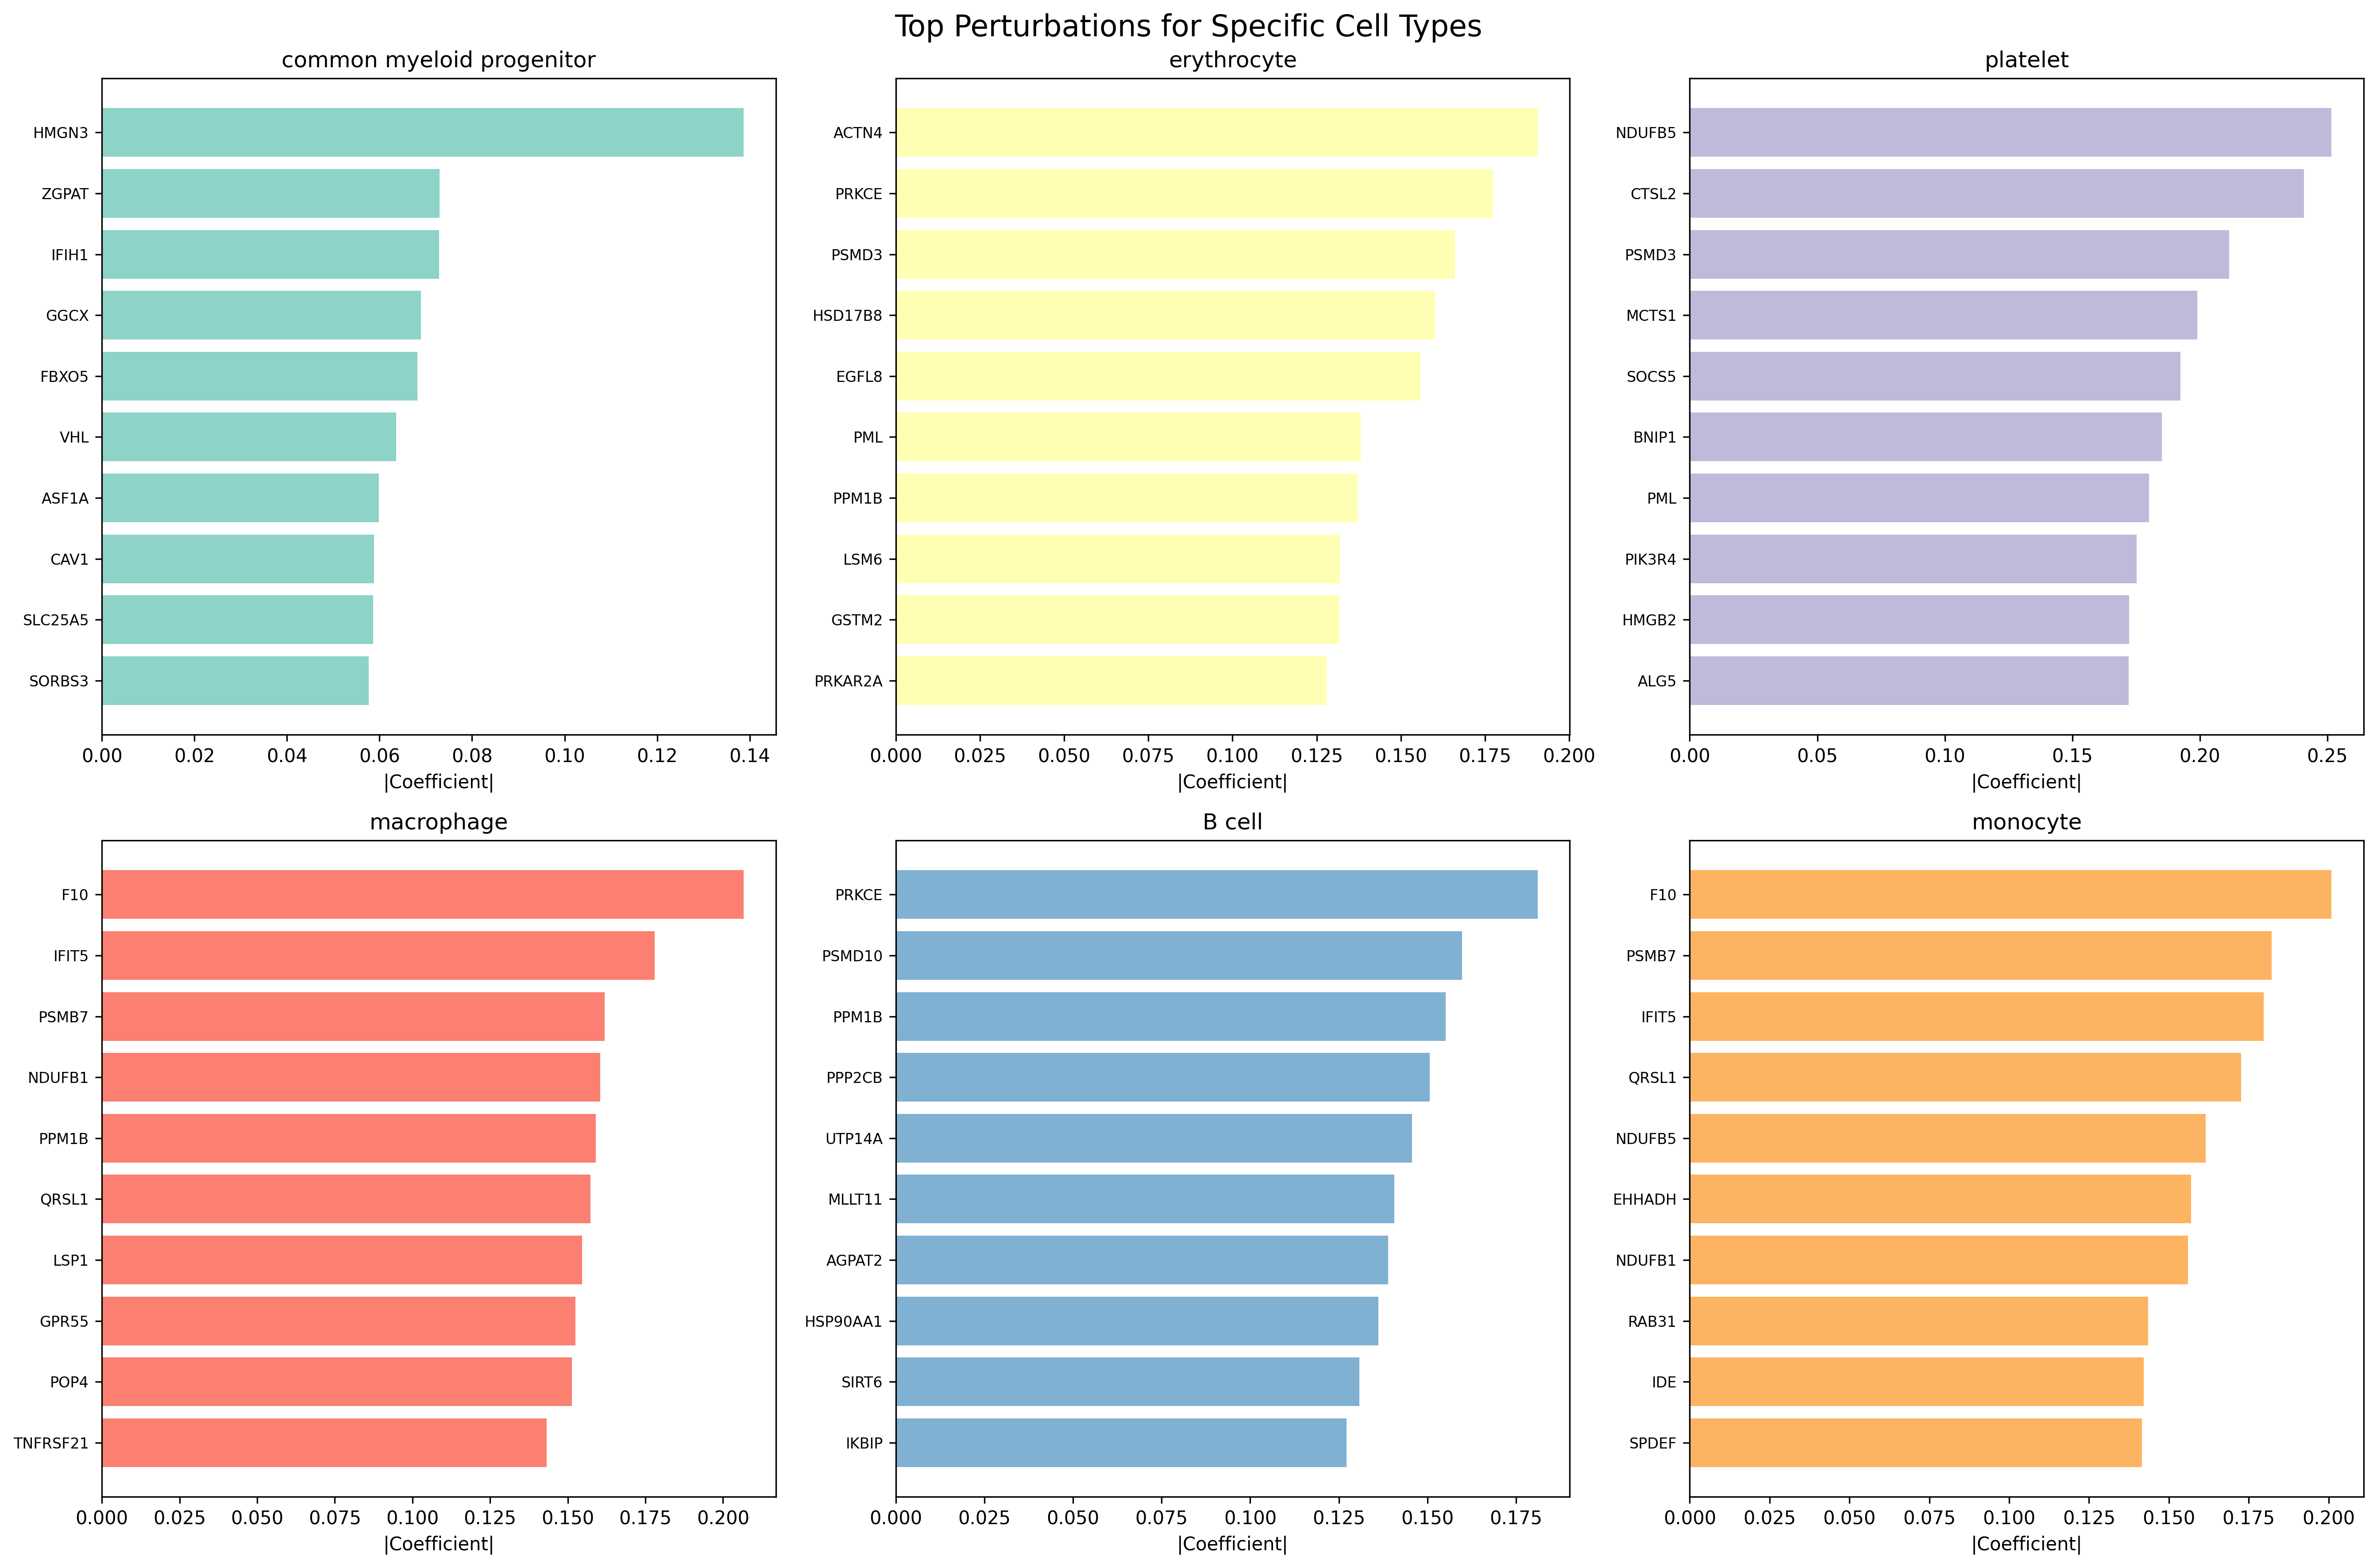

In [23]:
### 细胞类型特异性扰动分析
# 识别每个细胞类型的特异性扰动
cell_specific_perts = {}

for cell_type in cell_type_names:
    # 获取该细胞类型的系数
    cell_coefs = coef_matrix[cell_type]
    # 筛选非零且重要的扰动
    important_perts = cell_coefs[np.abs(cell_coefs) > 0.01].abs().sort_values(ascending=False)
    cell_specific_perts[cell_type] = important_perts.head(10)

# 可视化特定细胞类型的扰动
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, cell_type in enumerate(list(cell_specific_perts.keys())[:6]):
    perts = cell_specific_perts[cell_type]
    if len(perts) > 0:
        axes[i].barh(range(len(perts)), perts.values, color=plt.cm.Set3(i))
        axes[i].set_yticks(range(len(perts)))
        axes[i].set_yticklabels(perts.index, fontsize=8)
        axes[i].set_xlabel('|Coefficient|')
        axes[i].set_title(f'{cell_type}')
        axes[i].invert_yaxis()

plt.suptitle('Top Perturbations for Specific Cell Types', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
### 网络可视化
# 构建扰动-细胞类型关联网络
import networkx as nx

# 筛选强关联（系数绝对值>阈值）
threshold = 0.05
G = nx.Graph()

# 添加节点
for pert in perturbation_names:
    G.add_node(pert, node_type='perturbation')
for cell in cell_type_names:
    G.add_node(cell, node_type='cell_type')

# 添加边
for pert in perturbation_names:
    for cell in cell_type_names:
        coef = coef_matrix.loc[pert, cell]
        if abs(coef) > threshold:
            G.add_edge(pert, cell, weight=abs(coef), sign=np.sign(coef))

# 可视化网络（子图）
plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, k=1, iterations=50)

# 绘制节点
pert_nodes = [n for n, attr in G.nodes(data=True) if attr['node_type'] == 'perturbation']
cell_nodes = [n for n, attr in G.nodes(data=True) if attr['node_type'] == 'cell_type']

nx.draw_networkx_nodes(G, pos, nodelist=pert_nodes, 
                      node_color='lightcoral', node_size=300, alpha=0.8, label='Perturbations')
nx.draw_networkx_nodes(G, pos, nodelist=cell_nodes, 
                      node_color='lightblue', node_size=300, alpha=0.8, label='Cell Types')

# 绘制边（根据符号区分颜色）
edges = G.edges(data=True)
positive_edges = [(u, v) for u, v, d in edges if d['sign'] > 0]
negative_edges = [(u, v) for u, v, d in edges if d['sign'] < 0]

nx.draw_networkx_edges(G, pos, edgelist=positive_edges, 
                      edge_color='green', alpha=0.5, width=1)
nx.draw_networkx_edges(G, pos, edgelist=negative_edges, 
                      edge_color='red', alpha=0.5, width=1)

# 添加标签（仅显示重要节点）
important_nodes = list(perturbation_importance.head(15)['perturbation']) + \
                 list(performance_df[performance_df['r2_cv'] > 0.3].index)

nx.draw_networkx_labels(G, pos, 
                       labels={node: node for node in important_nodes if node in G.nodes()},
                       font_size=8)

plt.title('L1000 Perturbation - Blood Cell Type Association Network')
plt.legend()
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
### 模型验证
# 交叉验证评估
from sklearn.metrics import r2_score, mean_squared_error

cv_results = {}

for cell_type in cell_type_names[:10]:  # 选择前10个细胞类型验证
    y_true = Y_scaled[cell_type].values
    model = lasso_models[cell_type]
    y_pred = model.predict(X_scaled)
    
    cv_results[cell_type] = {
        'r2': r2_score(y_true, y_pred),
        'rmse': np.sqrt(mean_squared_error(y_true, y_pred)),
        'pearson_corr': np.corrcoef(y_true, y_pred)[0, 1]
    }

cv_df = pd.DataFrame(cv_results).T
print("交叉验证结果:")
print(cv_df)

# 可视化预测效果示例
example_cell = performance_df['r2_cv'].idxmax()  # 选择R²最高的细胞类型
y_true_example = Y_scaled[example_cell].values
y_pred_example = lasso_models[example_cell].predict(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(y_true_example, y_pred_example, alpha=0.6)
plt.plot([-3, 3], [-3, 3], 'r--', lw=2)
plt.xlabel('True Expression (Standardized)')
plt.ylabel('Predicted Expression (Standardized)')
plt.title(f'Prediction Performance: {example_cell}\nR² = {cv_df.loc[example_cell, "r2"]:.3f}')
plt.grid(True, alpha=0.3)
plt.show()

In [26]:
### 生物学意义解读
# 生成生物学洞察报告
print("=== Lasso回归分析关键发现 ===\n")

print("1. 预测能力强的细胞类型:")
top_predictable = performance_df.sort_values('r2_cv', ascending=False).head(5)
for cell, row in top_predictable.iterrows():
    print(f"   • {cell}: R² = {row['r2_cv']:.3f}, 使用 {int(row['non_zero_features'])} 个扰动")

print("\n2. 影响广泛的扰动:")
top_influential = perturbation_importance.head(5)
for _, row in top_influential.iterrows():
    print(f"   • {row['perturbation']}: 影响 {int(row['non_zero_count'])} 种细胞类型")

print("\n3. 细胞类型特异性发现:")
for cell_type in list(cell_specific_perts.keys())[:3]:
    top_pert = cell_specific_perts[cell_type].index[0] if len(cell_specific_perts[cell_type]) > 0 else "None"
    print(f"   • {cell_type} 最受 {top_pert} 影响")

=== Lasso回归分析关键发现 ===

1. 预测能力强的细胞类型:
   • neutrophil: R² = 0.394, 使用 463 个扰动
   • erythrocyte: R² = 0.390, 使用 410 个扰动
   • intermediate monocyte: R² = 0.338, 使用 437 个扰动
   • macrophage: R² = 0.332, 使用 441 个扰动
   • classical monocyte: R² = 0.324, 使用 431 个扰动

2. 影响广泛的扰动:
   • PRKCE: 影响 19 种细胞类型
   • NDUFB5: 影响 19 种细胞类型
   • PPM1B: 影响 19 种细胞类型
   • RGS4: 影响 19 种细胞类型
   • IFIT5: 影响 18 种细胞类型

3. 细胞类型特异性发现:
   • common myeloid progenitor 最受 HMGN3 影响
   • erythrocyte 最受 ACTN4 影响
   • platelet 最受 NDUFB5 影响
